### Import

In [2]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import cv2
import os
from pathlib import Path
import albumentations as A

### Path

In [ ]:
#Insert path to dataset manually or use environment variable
path = ""

metadata = pd.read_json( path + 'Fundus_CIMT_2903_Dataset/data_info.json')
retina_images = glob(path + 'Fundus_CIMT_2903_Dataset/images/*.png')

## Data Preprocessing Pipeline

In [30]:
class ImagePreprocessor:
    """
    Extensible image preprocessing pipeline.
    Add more techniques as methods and register them in techniques list.
    """
    
    def __init__(self):
        self.techniques = []
        
    def add_technique(self, name, func):
        """Add a preprocessing technique to the pipeline"""
        self.techniques.append((name, func))
        return self
    
    def process(self, img):
        """Apply all techniques in sequence"""
        for name, func in self.techniques:
            img = func(img)
        return img
    
    def process_batch(self, image_paths, output_dir, progress_interval=100):
        """Process all images and save to output directory"""
        os.makedirs(output_dir, exist_ok=True)
        
        print(f"Processing {len(image_paths)} images with {len(self.techniques)} technique(s)...\n")
        processed_count = 0
        
        for i, img_path in enumerate(image_paths):
            img = cv2.imread(img_path)
            if img is None:
                print(f"Failed to read: {img_path}")
                continue
            
            # Convert BGR to RGB for processing
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # Apply pipeline
            processed = self.process(img_rgb)
            
            # Convert back to BGR for saving
            processed_bgr = cv2.cvtColor(processed, cv2.COLOR_RGB2BGR)
            
            # Save
            output_path = os.path.join(output_dir, Path(img_path).name)
            cv2.imwrite(output_path, processed_bgr)
            processed_count += 1
            
            if (i + 1) % progress_interval == 0:
                print(f"Processed {i + 1}/{len(image_paths)} images...")
        
        print(f"\nDone!")
        print(f"Total processed: {processed_count}/{len(image_paths)}")
        print(f"Saved to: {output_dir}")


# Define preprocessing techniques
def technique_remove_overlay(img):
    """Remove text overlay from top-left corner"""
    return remove_top_left_overlay(img)[0]

def remove_top_left_overlay(img, width=90, height=50, white_threshold=200):
    """
    Args:
        img: Image array (RGB or BGR)
        width: Width of area to check (default 90)
        height: Height of area to check (default 50)
        white_threshold: Pixel value considered white (default 200)
    
    Returns:
        Modified image with top-left blacked out if needed
    """
    img_copy = img.copy()
    
    # Get top-left region
    top_left = img_copy[:height, :width]
    
    # Convert to grayscale to check intensity
    if len(top_left.shape) == 3:
        gray = cv2.cvtColor(top_left, cv2.COLOR_RGB2GRAY)
    else:
        gray = top_left
    
    # Count white pixels
    white_pixels = np.sum(gray > white_threshold)
    
    # Replace with fixed dark color if there's any white pixel
    if white_pixels > 0:
        fill_color = np.array([6, 6, 6], dtype=img_copy.dtype)
        img_copy[:height, :width] = fill_color
        return img_copy, True
    
    return img_copy, False

def technique_randaug(img):
    """
    Medically-safe augmentation pipeline. 
    """
    transform = A.Compose([
        # Geometric variety without losing the fundus circle
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Affine(rotate=(-10, 10), scale=(0.98, 1.02), p=0.5),
        
        # We limit brightness to 5% to prevent 'burnout'
        A.RandomBrightnessContrast(brightness_limit=0.05, contrast_limit=0.05, p=0.5),
        
        A.OneOf([
            # Simulates slight patient movement
            A.MotionBlur(blur_limit=3, p=0.5), 
            
            # Simulates an out-of-focus lens
            A.GaussianBlur(blur_limit=3, p=0.5),
            
        ], p=0.4), # Apply blur to 40% of images
    ])
    
    return transform(image=img)['image']

def technique_CLAHE(img):
    """Apply CLAHE to enhance local contrast"""
    # 1. Split the image into R, G, and B channels
    r, g, b = cv2.split(img)
    
    # 2. Initialize CLAHE
    # clipLimit=2.0 prevents over-amplifying the noise in the blue channel
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    
    # 3. Apply CLAHE to the green channel only, as it contains the most relevant information for retinal images
    g_enhanced = clahe.apply(g)
    
    # 4. Merge the enhanced channels back together
    img_enhanced = cv2.merge((r, g_enhanced, b))
    
    return img_enhanced

# Create pipeline and add techniques
preprocessor = ImagePreprocessor()
preprocessor.add_technique("remove_overlay", technique_remove_overlay)
preprocessor.add_technique("randaug", technique_randaug)
preprocessor.add_technique("CLAHE", technique_CLAHE)

print("Pipeline created with techniques:")
for name, _ in preprocessor.techniques:
    print(f"  - {name}")

Pipeline created with techniques:
  - remove_overlay
  - randaug
  - CLAHE


In [24]:
# Run the preprocessing pipeline on all images
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
output_dir = path + "Fundus_CIMT_2903_Dataset/images_preprocessed/"

preprocessor.process_batch(retina_images, output_dir, progress_interval=100)

Processing 5806 images with 2 technique(s)...

Processed 100/5806 images...
Processed 200/5806 images...
Processed 300/5806 images...
Processed 400/5806 images...
Processed 500/5806 images...
Processed 600/5806 images...
Processed 700/5806 images...
Processed 800/5806 images...
Processed 900/5806 images...
Processed 1000/5806 images...
Processed 1100/5806 images...
Processed 1200/5806 images...
Processed 1300/5806 images...
Processed 1400/5806 images...
Processed 1500/5806 images...
Processed 1600/5806 images...


KeyboardInterrupt: 

## Testing

### Test CLAHE

Testing clahe on a sample image...


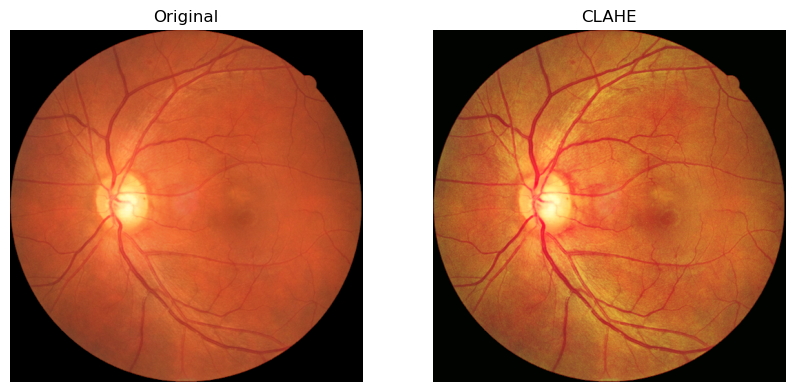

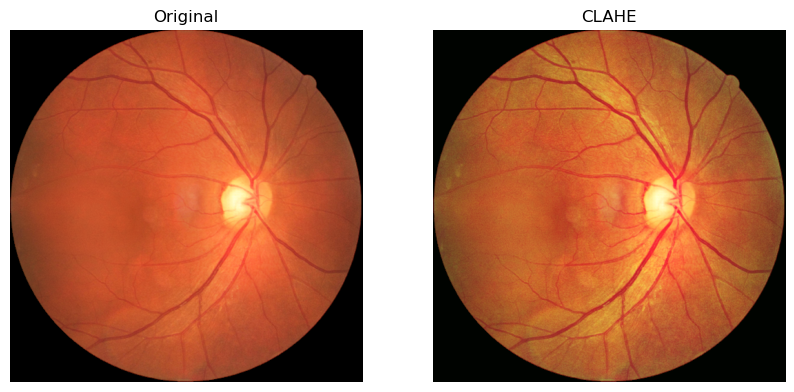

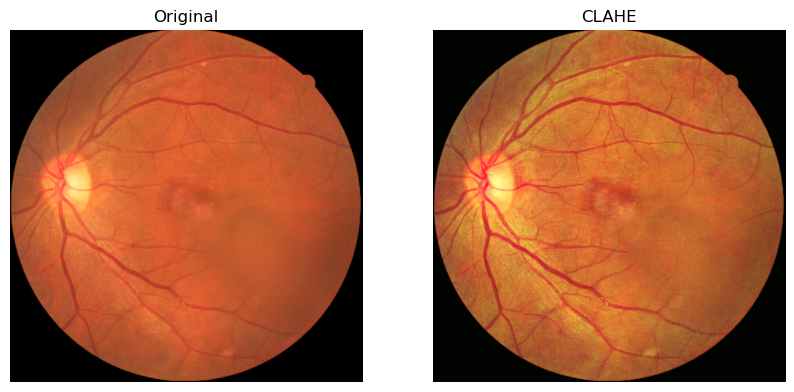

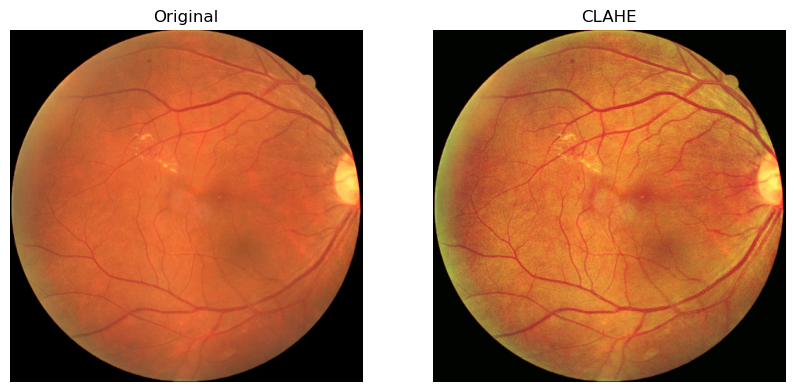

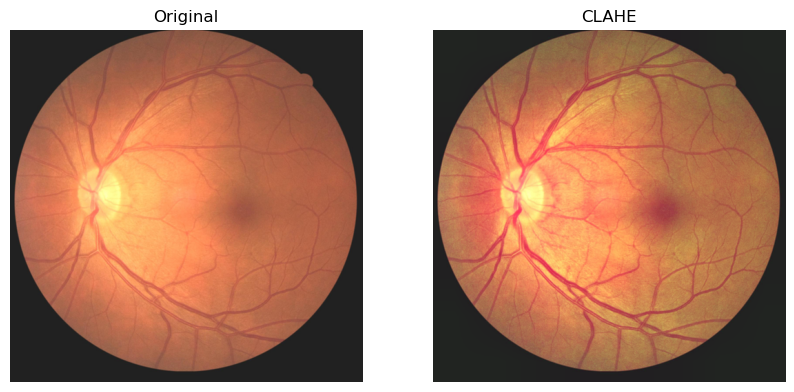

In [31]:
# Test CLAHE on 5 sample images
print("Testing clahe on a sample image...")

sample_paths = retina_images[:5]
for img_path in sample_paths:
    img = cv2.imread(img_path)
    if img is None:
        print(f"Failed to read: {img_path}")
        continue
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_clahe = technique_CLAHE(img_rgb)
    
    # Display original and CLAHE images side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_rgb)
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(img_clahe)
    axes[1].set_title("CLAHE")
    axes[1].axis('off')
    
    plt.show()

### Test Random Augmentation

Testing random augmentation on sample images...

249815003_R.png: Generated 3 augmented versions
520876001_L.png: Generated 3 augmented versions
556895001_L.png: Generated 3 augmented versions


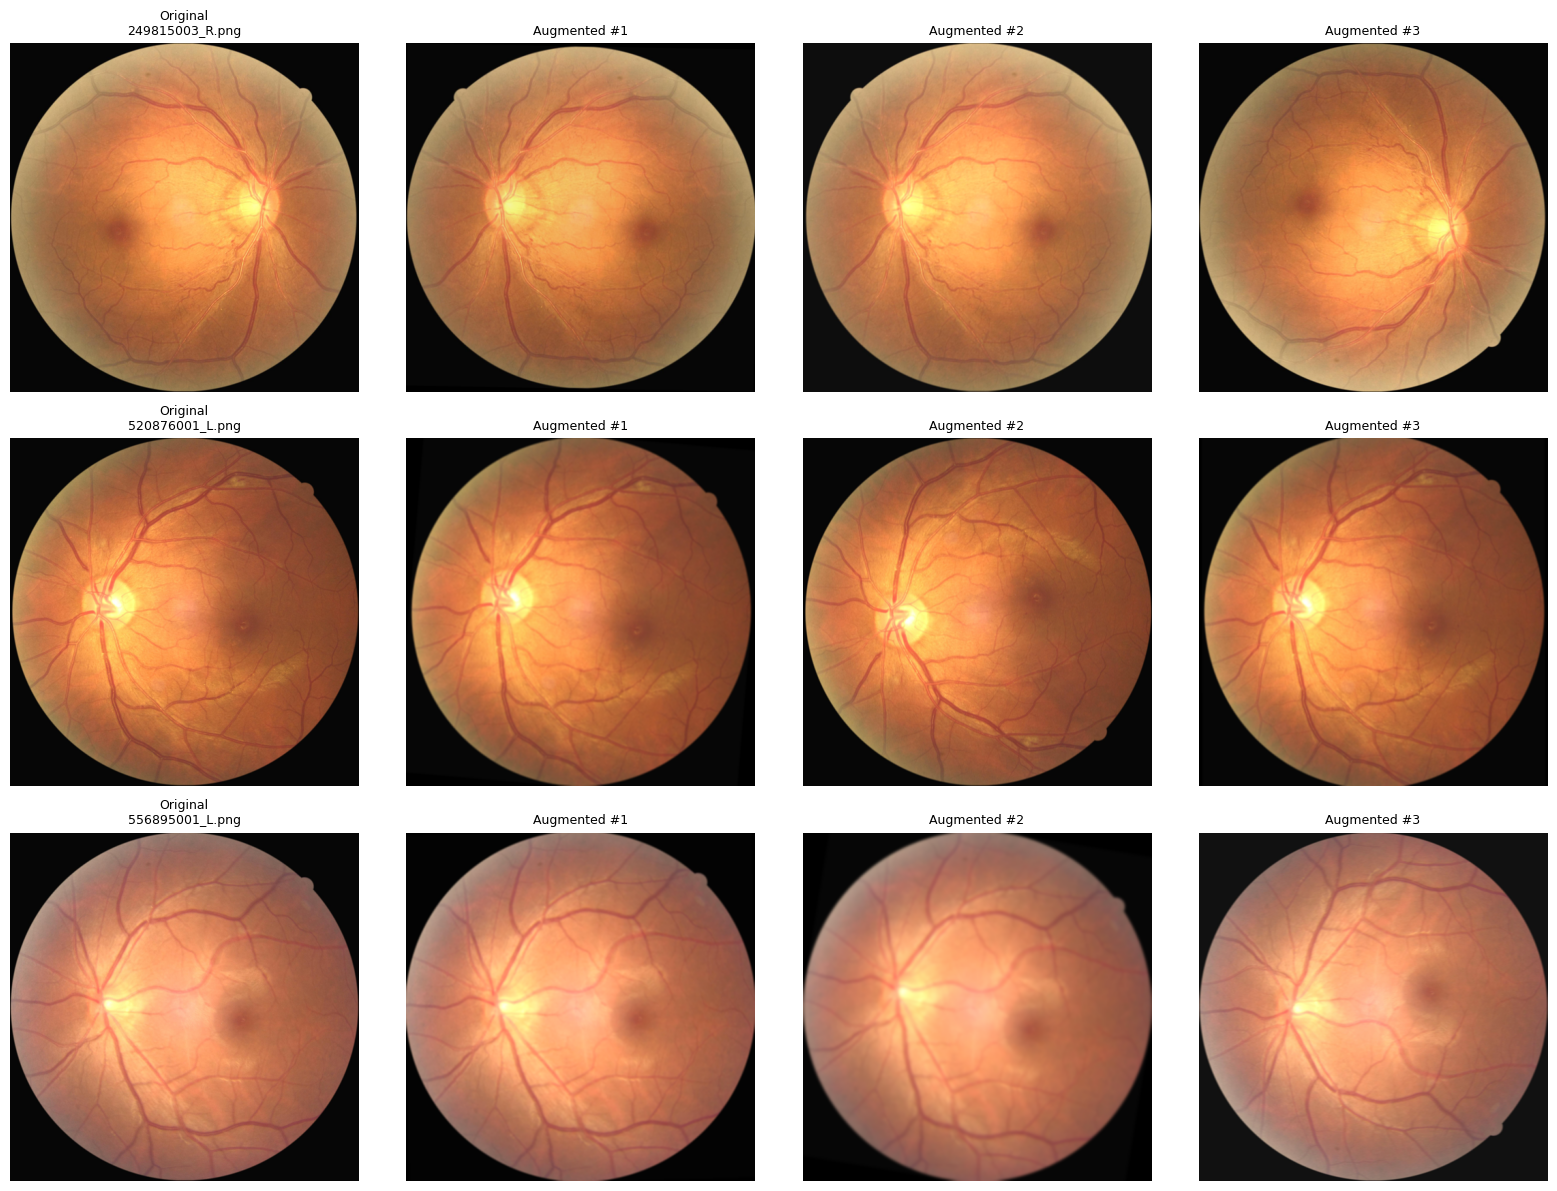


Augmentation pipeline includes:
  - HorizontalFlip (p=0.5)
  - VerticalFlip (p=0.5)
  - Affine rotation (-10° to +10°, p=0.5)
  - RandomBrightnessContrast (±5%, p=0.5)
  - OneOf: MotionBlur or GaussianBlur (p=0.4)


In [23]:
# Test random augmentation on 3 sample images, showing multiple augmentations
print("Testing random augmentation on sample images...\n")

# Pick 3 random images from the dataset
np.random.seed(42)  # For reproducibility
sample_paths = np.random.choice(retina_images, size=min(3, len(retina_images)), replace=False)

# Show original + 3 augmented versions for each image
num_augmentations = 3
fig, axes = plt.subplots(len(sample_paths), num_augmentations + 1, 
                        figsize=(16, 4 * len(sample_paths)))

if len(sample_paths) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, img_path in enumerate(sample_paths):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print(f"Failed to read: {img_path}")
        continue
    
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Show original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Original\n{Path(img_path).name}", fontsize=9)
    axes[i, 0].axis('off')
    
    # Show multiple augmented versions
    for j in range(num_augmentations):
        augmented = technique_randaug(img.copy())
        axes[i, j + 1].imshow(augmented)
        axes[i, j + 1].set_title(f"Augmented #{j+1}", fontsize=9)
        axes[i, j + 1].axis('off')
    
    print(f"{Path(img_path).name}: Generated {num_augmentations} augmented versions")

plt.tight_layout()
plt.show()

print("\nAugmentation pipeline includes:")
print("  - HorizontalFlip (p=0.5)")
print("  - VerticalFlip (p=0.5)")
print("  - Affine rotation (-10° to +10°, p=0.5)")
print("  - RandomBrightnessContrast (±5%, p=0.5)")
print("  - OneOf: MotionBlur or GaussianBlur (p=0.4)")

### Testing overlay removal

Testing overlay removal on top 5 images with white pixels...

432332001_L.png: Overlay removed
432332001_R.png: Overlay removed
429484001_R.png: Overlay removed
429484001_L.png: Overlay removed
152584002_R.png: Overlay removed


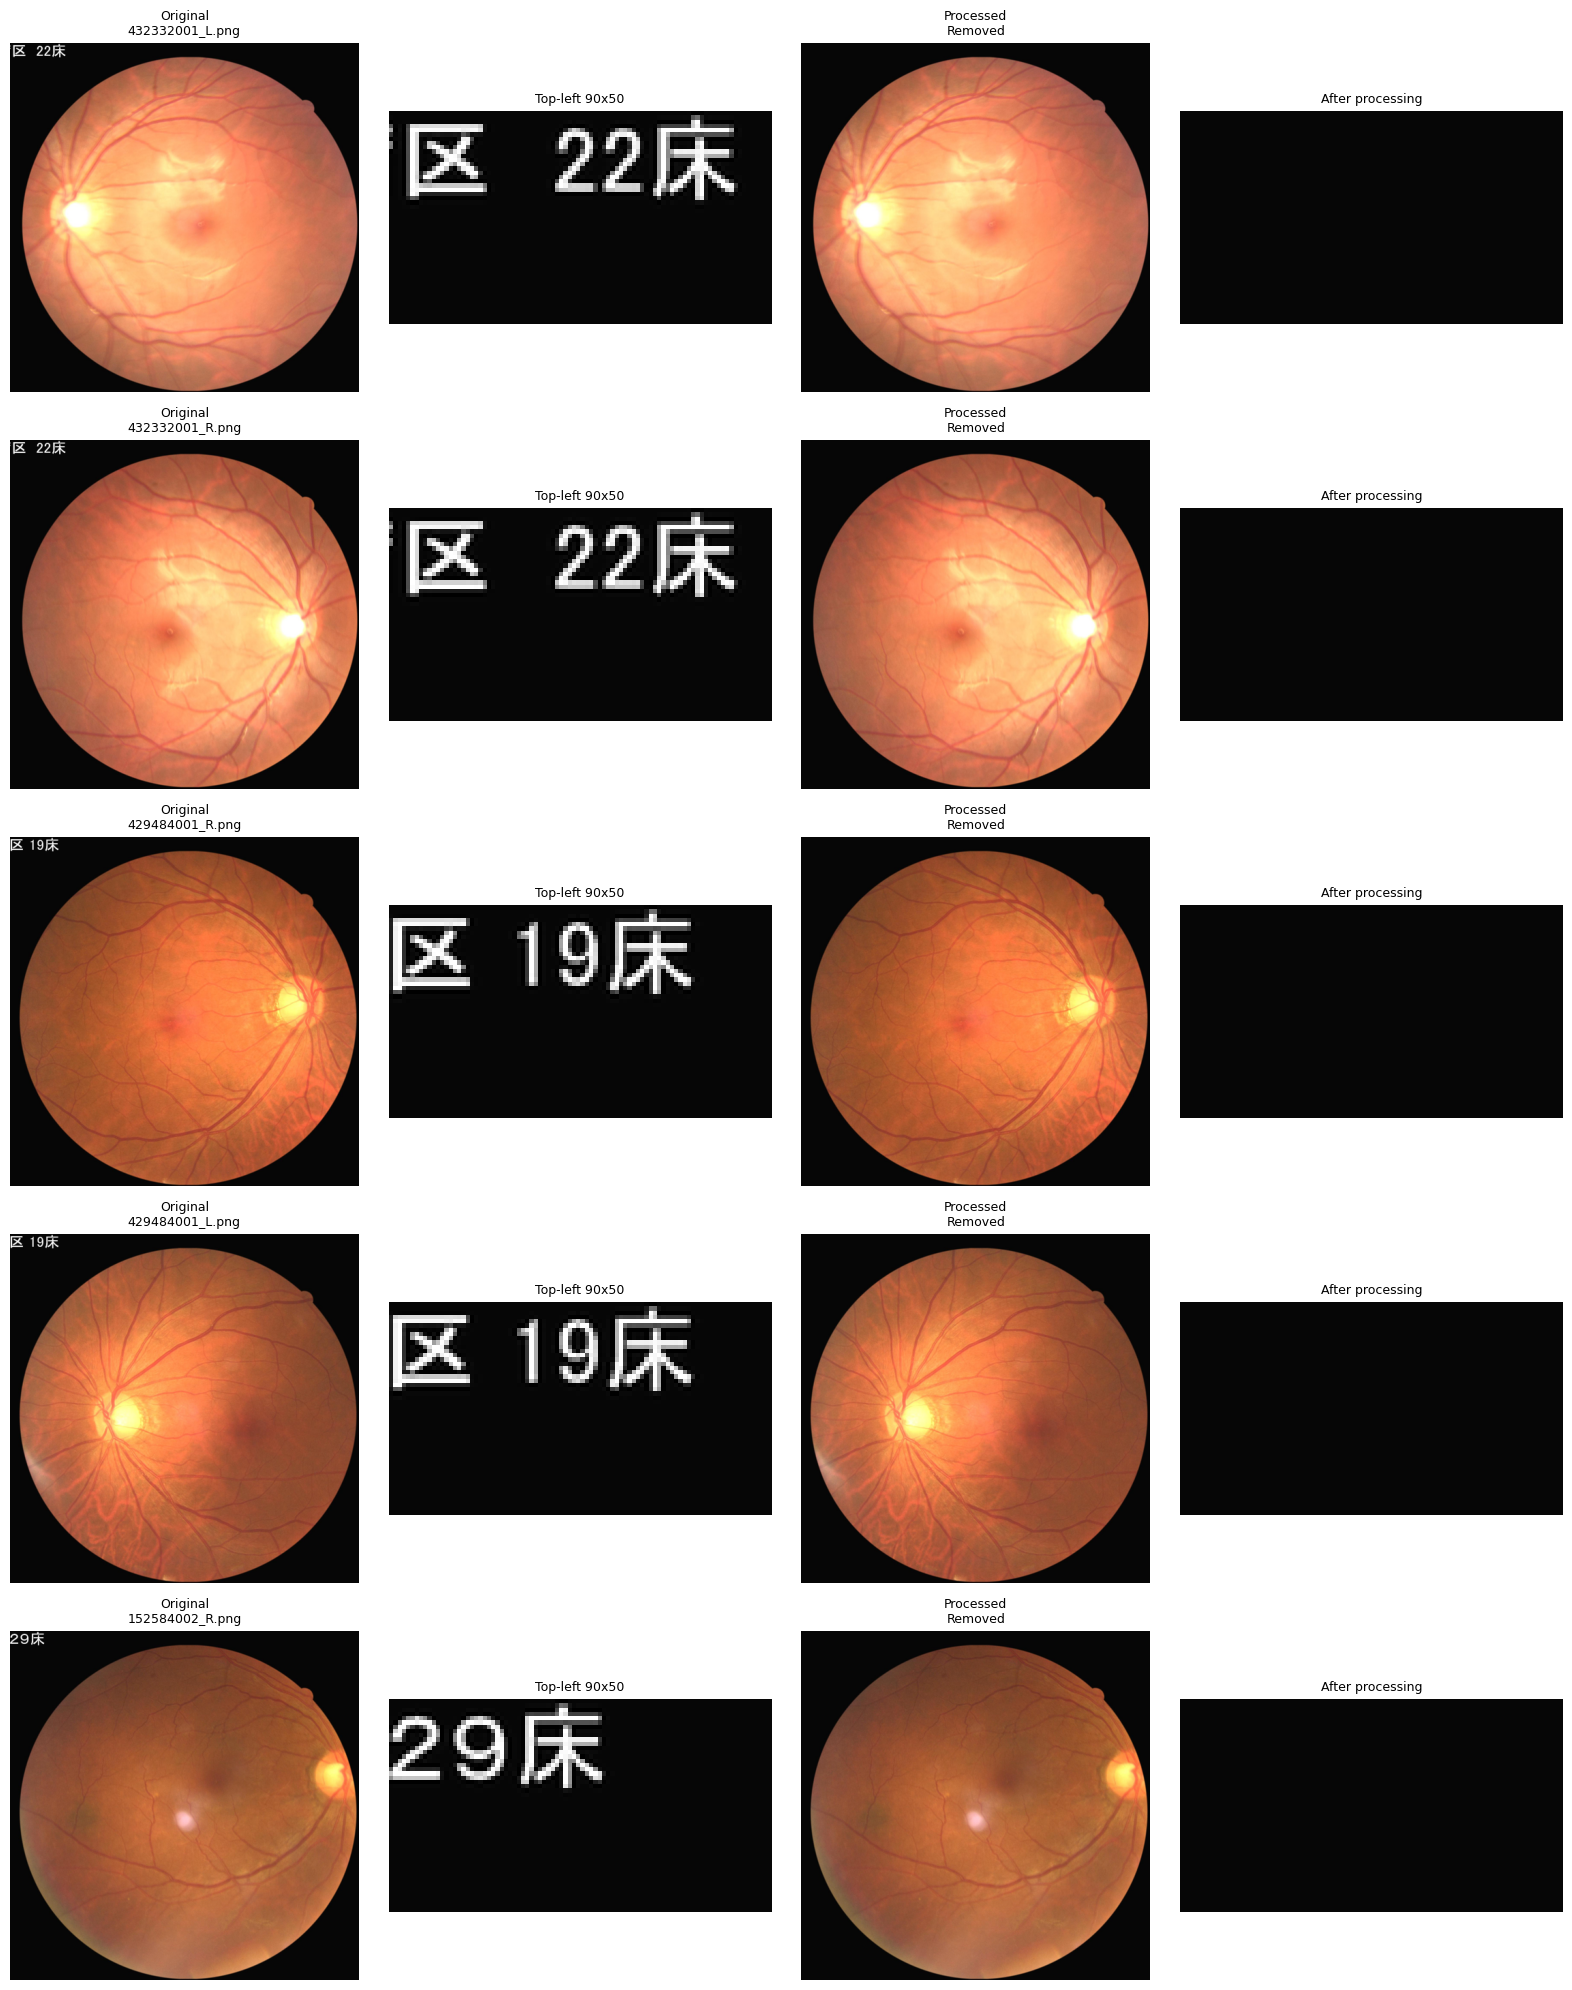

In [17]:
# Test on the top 5 images with white pixels in the top-left region
print("Testing overlay removal on top 5 images with white pixels...\n")

scores = []
for p in retina_images:
    img = cv2.imread(p)
    if img is None:
        continue
    top_left = img[:50, :90]
    gray = cv2.cvtColor(top_left, cv2.COLOR_BGR2GRAY)
    white_pixels = int(np.sum(gray > 200))
    if white_pixels > 0:
        scores.append((white_pixels, p))

scores.sort(reverse=True)
sample_paths = [p for _, p in scores[:5]]

if not sample_paths:
    print("No images with white pixels found in the top-left region.")
else:
    fig, axes = plt.subplots(len(sample_paths), 4, figsize=(16, 4 * len(sample_paths)))
    if len(sample_paths) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, img_path in enumerate(sample_paths):
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            continue
        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        # Original
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Original\n{Path(img_path).name}", fontsize=9)
        axes[i, 0].axis('off')
        
        # Top-left zoom
        axes[i, 1].imshow(img[:50, :90])
        axes[i, 1].set_title("Top-left 90x50", fontsize=9)
        axes[i, 1].axis('off')
        
        # Processed
        processed, had_overlay = remove_top_left_overlay(img)
        axes[i, 2].imshow(processed)
        axes[i, 2].set_title(f"Processed\n{'Removed' if had_overlay else 'No overlay'}", fontsize=9)
        axes[i, 2].axis('off')
        
        # Processed top-left zoom
        axes[i, 3].imshow(processed[:50, :90])
        axes[i, 3].set_title("After processing", fontsize=9)
        axes[i, 3].axis('off')
        
        print(f"{Path(img_path).name}: {'Overlay removed' if had_overlay else 'No overlay detected'}")

    plt.tight_layout()
    plt.show()